# Criminal Activity Reports 
The Monthly Criminal Activity dataset tracks the instances of police reports each month from the year 2024 to 2026. Here we will analyze the data to determine the neighborhood with the highest crime rate. Each row of the dataset details the date, time, type, and location of the crime occurred.

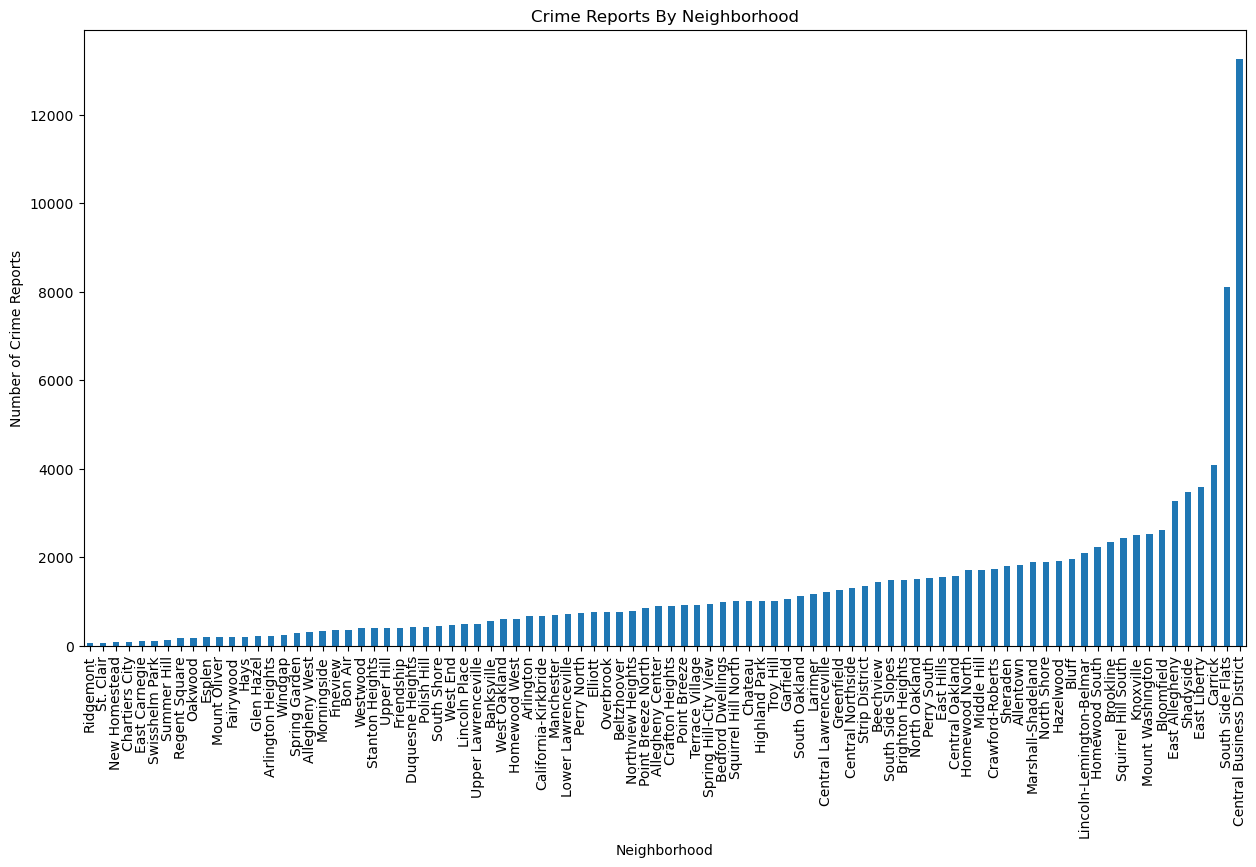

In [2]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as py

crimeData = pd.read_csv("MonthlyCrime2024-26.csv", low_memory = False)

# Fix double hyphens to single hyphens
crimeData["Neighborhood"] = crimeData["Neighborhood"].str.replace("–", "-", regex=False)

totalCrime = crimeData.groupby("Neighborhood").count()["NIBRS_Offense_Category"].sort_values(ascending = True)
totalCrime.plot(title = "Crime Reports By Neighborhood",kind = "bar", figsize = (15,8), ylabel = "Number of Crime Reports")
plt.show()

In [3]:
# display 5 most crimes and 5 least crimes
totalCrime

Neighborhood
Ridgemont                       56
St. Clair                       63
New Homestead                   83
Chartiers City                  88
East Carnegie                  103
                             ...  
Shadyside                     3481
East Liberty                  3582
Carrick                       4080
South Side Flats              8101
Central Business District    13259
Name: NIBRS_Offense_Category, Length: 90, dtype: int64

In [5]:
monthCrime = pd.DataFrame(crimeData).dropna()
# create dictionary
crimeType = {}

# iterate through each row of data frame
for index, row in monthCrime.iterrows():
    # collect crime type from data frame 
    crime = row['NIBRS_Offense_Type']

    # check if item is in dict; if so increment occurence by 1, otherwise create new key value pair
    if crime in crimeType:
        crimeType[crime] += 1
    else:
        crimeType[crime] = 1

# display dict in alphabetical order
for key, value in sorted(crimeType.items()):
    print(f"{key}: {value}")

Aggravated Assault: 2617
All Other Larceny: 4411
All other Offenses: 6205
Arson: 349
Assisting or Promoting Prostitution: 47
Bad Checks: 73
Bribery: 2
Burglary/Breaking & Entering: 2216
Commercial Sex Acts: 4
Counterfeiting/Forgery: 383
Credit Card/ATM Fraud: 1883
Curfew/Loiting/Vagrancy Violations: 265
Destruction/Damage/Vandalism of Property: 8304
Disorderly Conduct: 5451
Driving Under the Influence: 1308
Drug Equipment Violations: 3460
Drug/Narcotic Violations: 5881
Drunkenness: 618
Embezzlement: 12
Extortion/Blackmail: 161
False Pretenses/Swindle/Confidence Game: 1458
Family Offenses, Nonviolent: 436
Hacking/Computer Invasion: 62
Impersonation: 1235
Intimidation: 6383
Involuntary Servitude: 2
Kidnapping/Abduction: 235
Liquor Law Violaitons: 47
Motor Vehicle Theft: 3240
Murder & Nonnegligent Manslaughter: 101
Negligent Manslaughter: 6
Not NIBRS Reportable: 18512
Peeping Tom: 9
Pocket-Picking: 72
Pornography/Obscene Material: 102
Prostitution: 42
Purse-snatching: 93
Robbery: 1139
Sho

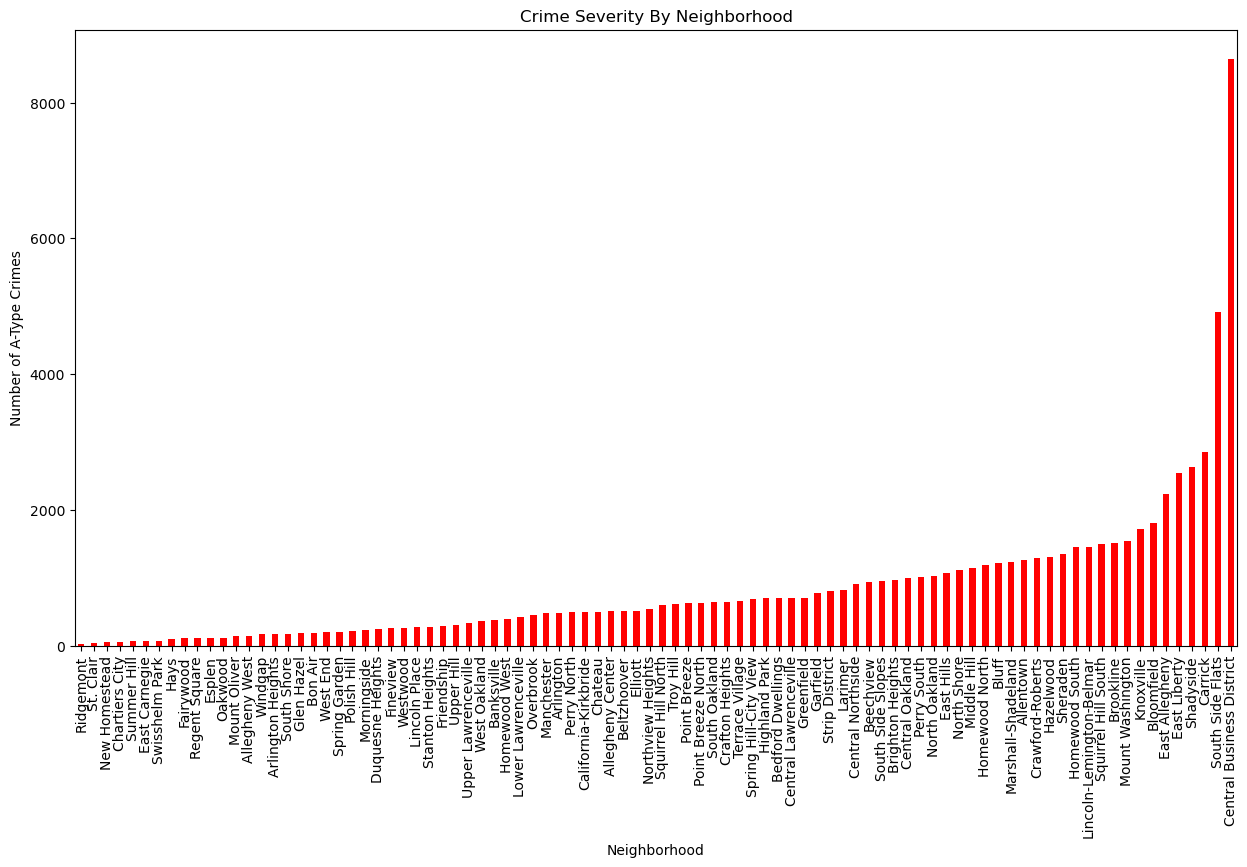

Neighborhood
Ridgemont                      25
St. Clair                      38
New Homestead                  48
Chartiers City                 56
Summer Hill                    72
                             ... 
East Liberty                 2543
Shadyside                    2628
Carrick                      2852
South Side Flats             4908
Central Business District    8640
Name: NIBRS_Offense_Grouping, Length: 90, dtype: int64


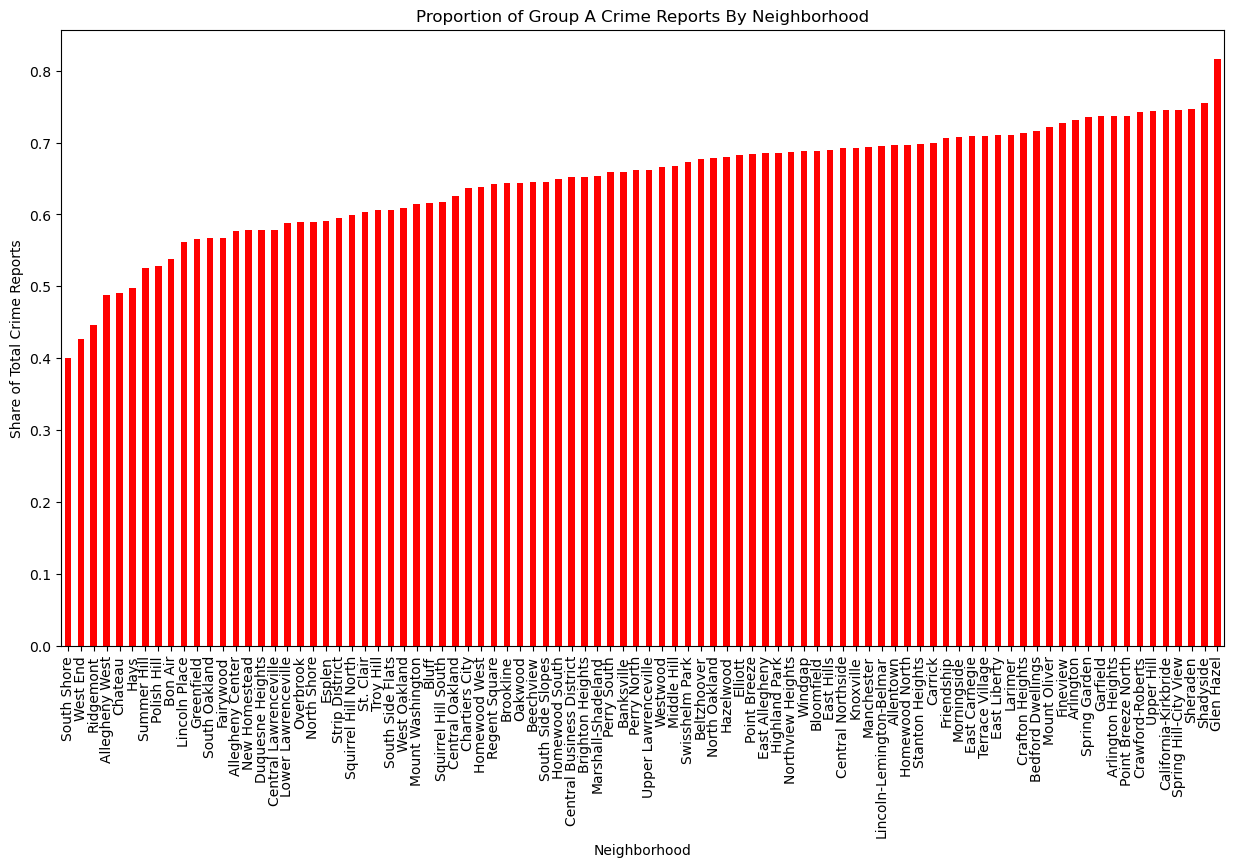

Neighborhood
South Shore              0.400000
West End                 0.427015
Ridgemont                0.446429
Allegheny West           0.488525
Chateau                  0.490138
                           ...   
California-Kirkbride     0.745482
Spring Hill-City View    0.745708
Sheraden                 0.746252
Shadyside                0.754955
Glen Hazel               0.816143
Name: NIBRS_Offense_Grouping, Length: 90, dtype: float64


In [33]:
typeA = crimeData[crimeData['NIBRS_Offense_Grouping'] == 'A']
severity = typeA.groupby('Neighborhood')['NIBRS_Offense_Grouping'].count().sort_values(ascending=True)
severity.plot(
    title = "Crime Severity By Neighborhood",
    kind = "bar", 
    figsize = (15,8), 
    ylabel = "Number of A-Type Crimes",
    color = "red")
plt.show()
print(severity)

severity_ratio = (severity / totalCrime).sort_values(ascending=True)
severity_ratio.plot(
    title="Proportion of Group A Crime Reports By Neighborhood",
    kind="bar",
    figsize=(15, 8),
    ylabel="Share of Total Crime Reports",
    color="red"
)
plt.show()
print(severity_ratio)

In [38]:
totalCrime_df = totalCrime.to_frame(name="Crime_Count").reset_index()

# Assign to list for final conclusion use
crimeScore = {}
for neighborhood, count in zip(totalCrime_df["Neighborhood"], totalCrime_df["Crime_Count"]):
    result = 1 - (int(count) / 13259)
    crimeScore[neighborhood] = result
    
totalCrime_df['Severity_Ratio'] = totalCrime_df['Neighborhood'].map(severity_ratio)
totalCrime_df['Weighted_Crime'] = totalCrime_df['Crime_Count'].astype(int) * (1 + totalCrime_df['Severity_Ratio'].astype(float) * 3)

min_wc = totalCrime_df['Weighted_Crime'].min()
max_wc = totalCrime_df['Weighted_Crime'].max()

totalCrime_df['Safety_Score'] = 100 - ((totalCrime_df['Weighted_Crime'] - min_wc) / (max_wc - min_wc)) * 100

print(totalCrime_df[["Neighborhood", "Safety_Score"]].to_string(
    index = False, 
    justify = "left", 
    col_space = 10, 
    float_format = "%.4f", 
    formatters = {"Neighborhood": "{:<25}".format})
)

Neighborhood               Safety_Score
Ridgemont                 100.0000     
St. Clair                  99.8822     
New Homestead              99.7541     
Chartiers City             99.6799     
East Carnegie              99.5109     
Swisshelm Park             99.4622     
Summer Hill                99.4315     
Regent Square              99.0166     
Oakwood                    99.0064     
Esplen                     98.9654     
Mount Oliver               98.7298     
Fairywood                  98.9577     
Hays                       99.0396     
Glen Hazel                 98.3661     
Arlington Heights          98.4609     
Windgap                    98.4429     
Spring Garden              98.0358     
Allegheny West             98.4096     
Morningside                97.6567     
Fineview                   97.4672     
Bon Air                    97.9589     
Westwood                   97.2931     
Stanton Heights            97.1906     
Upper Hill                 96.9858     


# Conclusion
Ridgemont is the safest city based on the percentages given above. It has the least amount of crime incident reports compared to the rest, with a less severe aspect ratio in crime severity. 